In [5]:
from sklearn.metrics import (

    root_mean_squared_error, 
    mean_squared_error, 
    mean_absolute_error,
    mean_absolute_percentage_error,
    max_error,
    r2_score
)
import pandas as pd
import numpy as np

y_test = pd.read_csv("../data/y_test.csv")
predict_dtr = pd.read_csv("../data/predict_dtr.csv")
predict_hgbr = pd.read_csv("../data/predict_hgbr.csv")
predict_xgbr = pd.read_csv("../data/predict_xgbr.csv")
predict_lgbm = pd.read_csv("../data/predict_lgbm.csv")
predict_lgbm_bayesian = pd.read_csv("../data/predict_lgbm_bayesian.csv")
predict_lgbm_successive_halving = pd.read_csv("../data/predict_lgbm_successive_halving.csv")
predict_lgbm_cmaes = pd.read_csv("../data/predict_lgbm_cmaes.csv")


models = {
    "Decision Tree Regressor": predict_dtr,
    "HistGradient Boosting Regressor": predict_hgbr,
    "XGBoost Regressor": predict_xgbr,
    "LGBM Regressor": predict_lgbm
}

lgbm_with_different_paramaters = {
    "Default LGBM Regressor": predict_lgbm,
    "LGBM Regressor with Bayesian Optimization": predict_lgbm_bayesian,
    "LGBM Regressor with Successive Halving": predict_lgbm_successive_halving,
    "LGBM Regressor CMA-ES": predict_lgbm_cmaes
}

evaluation_results = []
evaluation_results_lgbm_with_different_paramaters = []


for model_name, prediction in models.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    
for model_name, prediction in lgbm_with_different_paramaters.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results_lgbm_with_different_paramaters.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    

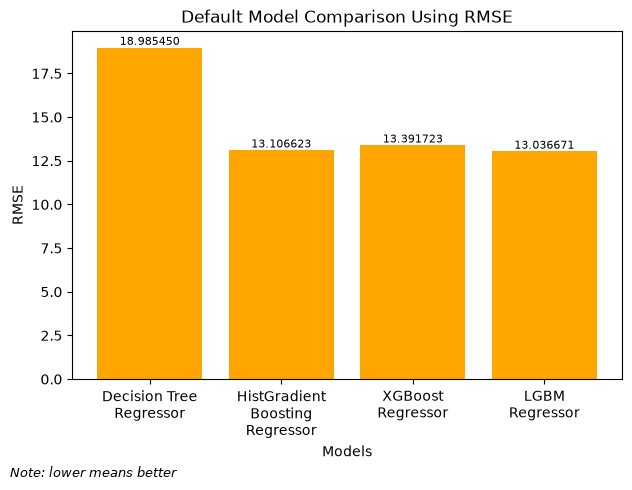

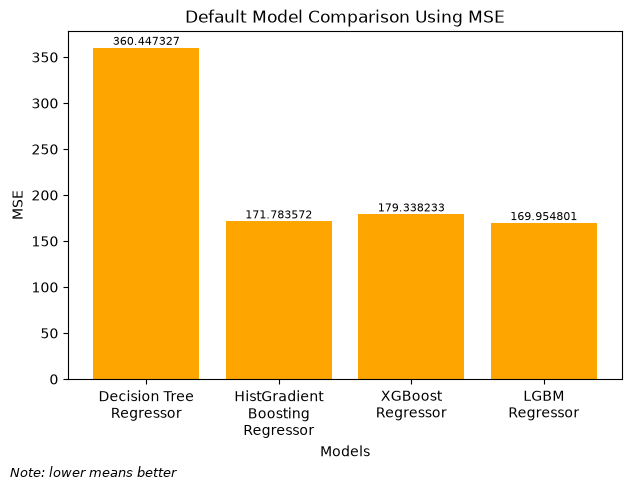

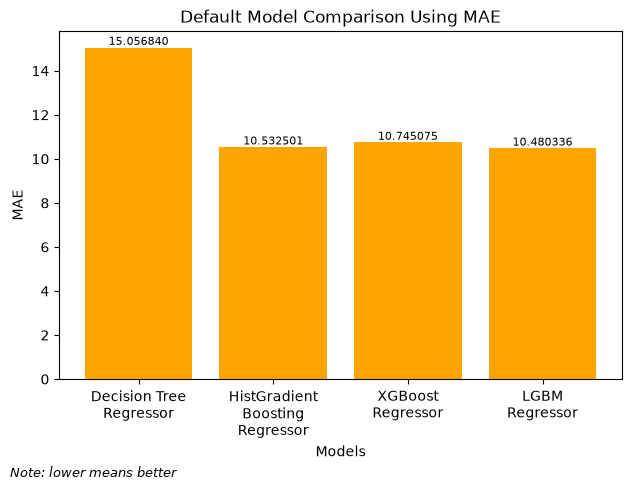

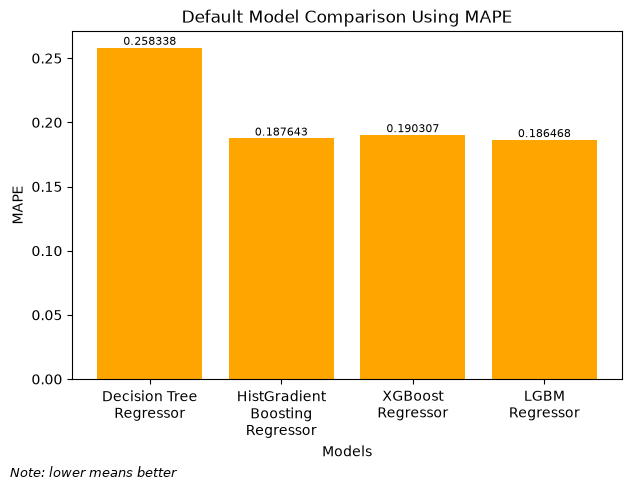

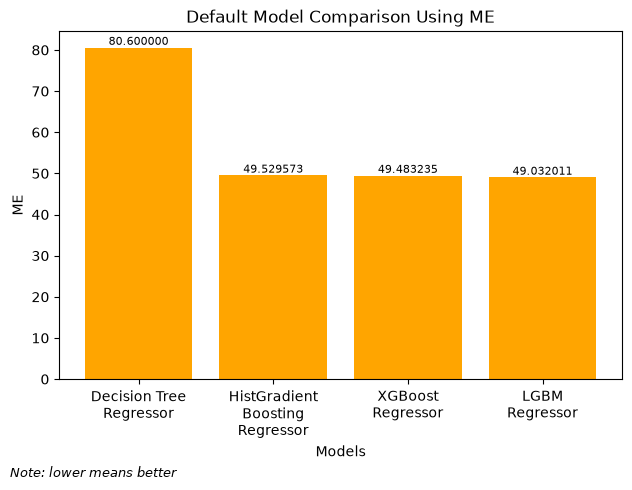

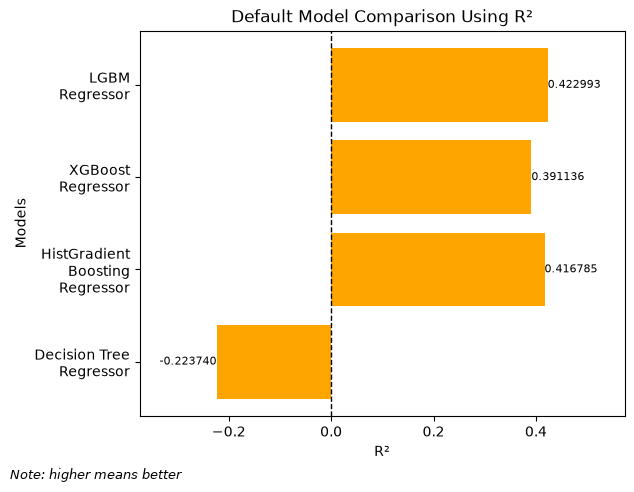

In [11]:
import matplotlib.pyplot as plt

results = np.array(evaluation_results, dtype=object)

models_name = ["Decision Tree\nRegressor", "HistGradient\nBoosting\nRegressor", "XGBoost\nRegressor", "LGBM\nRegressor"]
metrics_value = results[:, 1:].astype(float)
metrics_label = ["RMSE", "MSE", "MAE", "MAPE", "ME", "R²"]

for i, metric_name in enumerate(metrics_label):
    plt.figure()

    if metric_name == "R²":
        bars = plt.barh(models_name, metrics_value[:, i], color='orange')
        plt.xlabel(metric_name)
        plt.ylabel("Models")
        plt.axvline(0, color="black", linestyle="--", linewidth=1)
        plt.xlim(
            left=min(min(metrics_value[:, i]), 0) - 0.15,
            right=max(max(metrics_value[:, i]), 0) + 0.15
        )
        plt.figtext(
            0.15, 
            -0.01, 
            "Note: higher means better",
            ha="center",
            fontsize=9,
            style="italic",
        )
    else:
        bars = plt.bar(models_name, metrics_value[:, i], color='orange')
        plt.xlabel("Models")
        plt.ylabel(metric_name)
        plt.xticks(ha="center")
        plt.figtext(
            0.15,
            -0.005,
            "Note: lower means better",
            ha="center",
            fontsize=9,
            style="italic",
        )

    
    plt.bar_label(bars, fmt="%.6f", fontsize=8)
    plt.title(f"Default Model Comparison Using {metric_name}")
    plt.tight_layout()
    plt.savefig(
        f"../results/model_comparison/visualization_eval_default/{metric_name.replace('²', '2')}_default.png",
        dpi=300, 
        bbox_inches="tight"
    )
    plt.show()

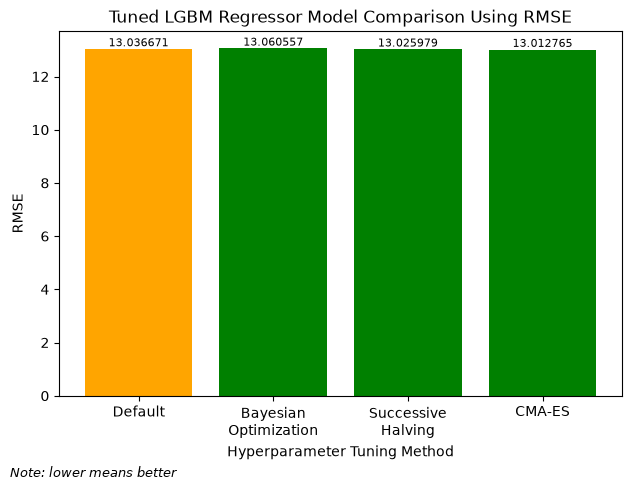

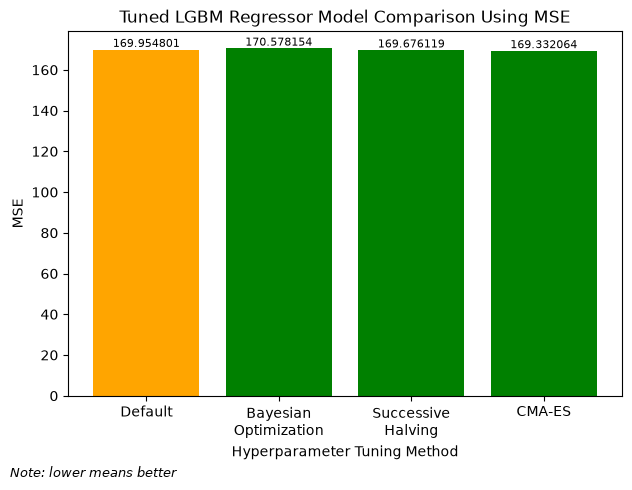

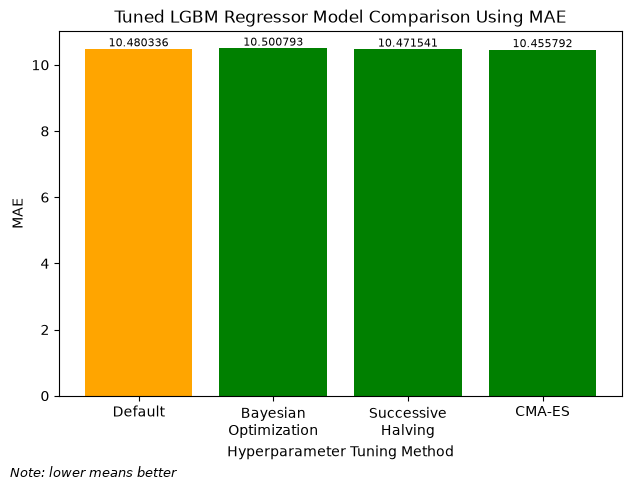

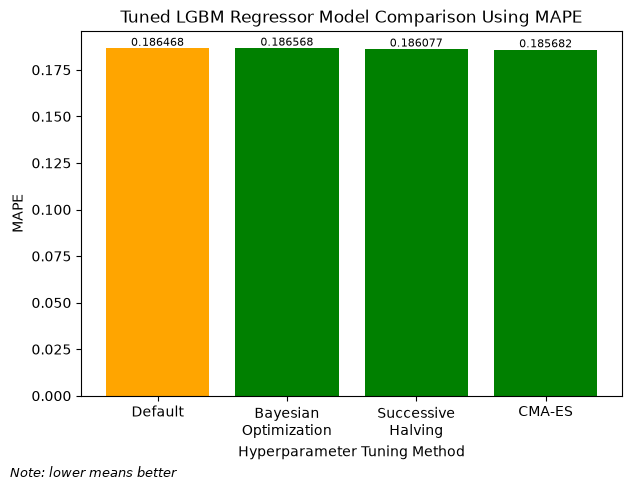

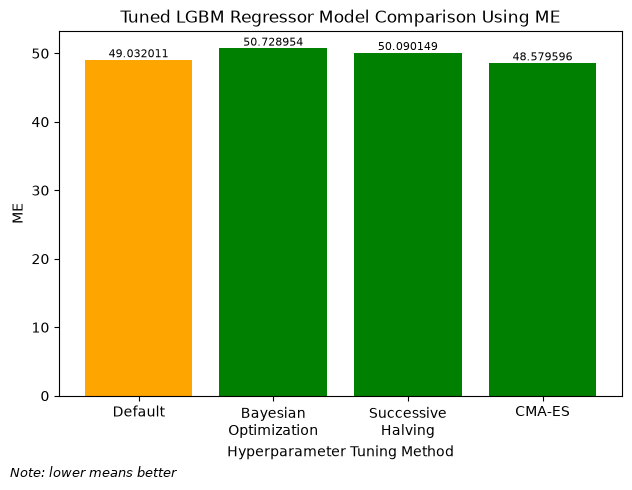

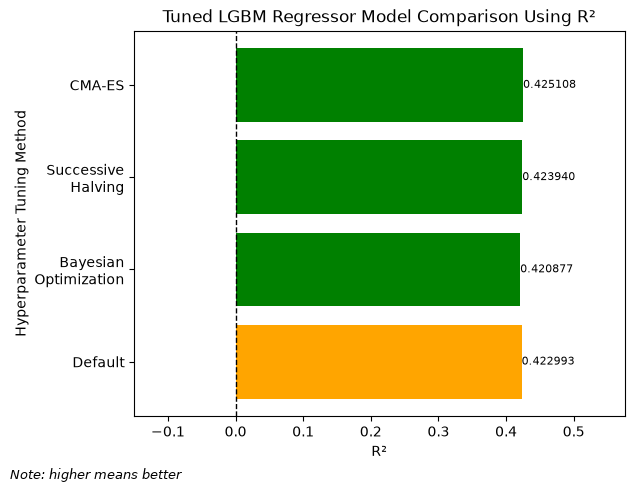

In [12]:
import matplotlib.pyplot as plt

results = np.array(evaluation_results_lgbm_with_different_paramaters, dtype=object)

hyperparameter_methods_name = ["Default", "Bayesian\nOptimization", "Successive\nHalving", "CMA-ES"]
metrics_value = results[:, 1:].astype(float)
metrics_label = ["RMSE", "MSE", "MAE", "MAPE", "ME", "R²"]
bar_colors = ['orange', 'green', 'green', 'green']

for i, metric_name in enumerate(metrics_label):
    plt.figure()

    if metric_name == "R²":
        bars = plt.barh(hyperparameter_methods_name, metrics_value[:, i], color=bar_colors)
        plt.xlabel(metric_name)
        plt.ylabel("Hyperparameter Tuning Method")
        plt.axvline(0, color="black", linestyle="--", linewidth=1)
        plt.xlim(
            left=min(min(metrics_value[:, i]), 0) - 0.15,
            right=max(max(metrics_value[:, i]), 0) + 0.15
        )
        plt.figtext(
            0.15, 
            -0.01, 
            "Note: higher means better",
            ha="center",
            fontsize=9,
            style="italic",
        )
    else:
        bars = plt.bar(hyperparameter_methods_name, metrics_value[:, i], color=bar_colors)
        plt.xlabel("Hyperparameter Tuning Method")
        plt.ylabel(metric_name)
        plt.xticks(ha="center")
        plt.figtext(
            0.15,
            -0.005,
            "Note: lower means better",
            ha="center",
            fontsize=9,
            style="italic",
        )

    
    plt.bar_label(bars, fmt="%.6f", fontsize=8)
    plt.title(f"Tuned LGBM Regressor Model Comparison Using {metric_name}")
    plt.tight_layout()
    plt.savefig(
        f"../results/model_comparison/visualization_eval_tuned/{metric_name.replace('²', '2')}_tuned.png",
        dpi=300, 
        bbox_inches="tight"
    )
    plt.show()

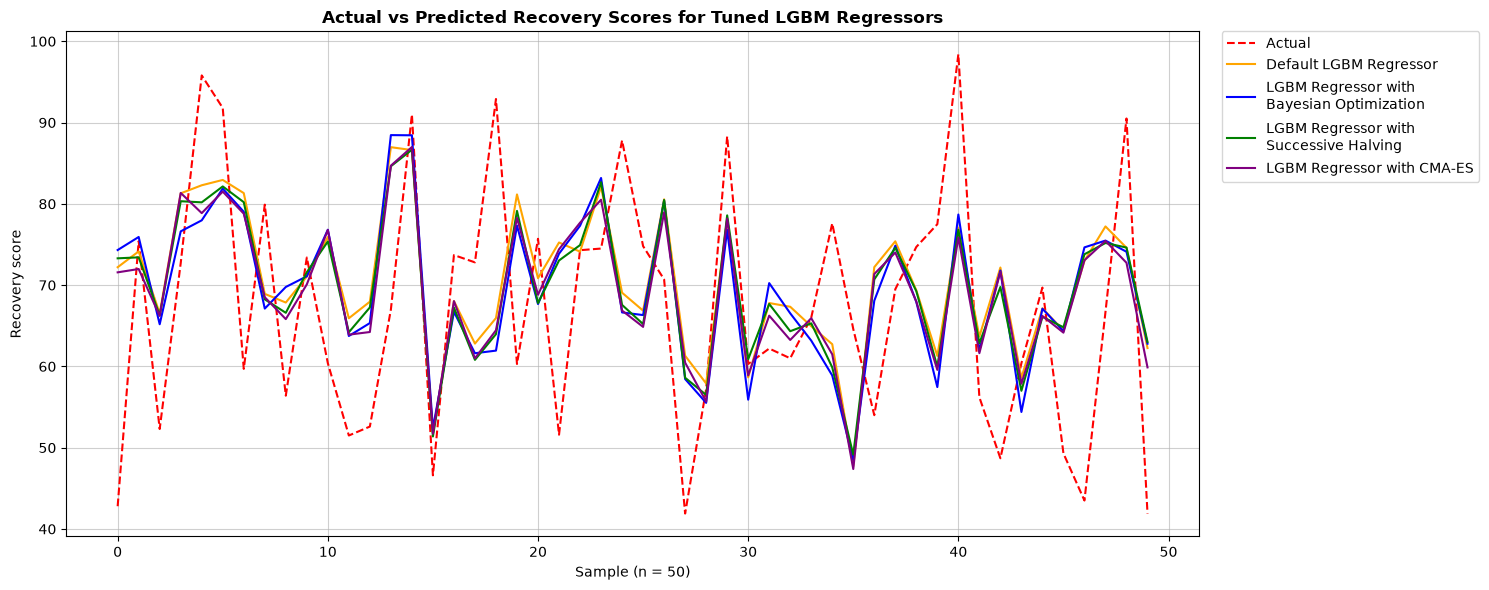

In [13]:
import matplotlib.pyplot as plt

sample_size = 50

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.iloc[:sample_size].values,
    label="Actual",
    color="red",
    linestyle="--",
)

models = [
    (predict_lgbm, "Default LGBM Regressor", "orange"),
    (predict_lgbm_bayesian, "LGBM Regressor with\nBayesian Optimization", "blue"),
    (predict_lgbm_successive_halving, "LGBM Regressor with\nSuccessive Halving", "green"),
    (predict_lgbm_cmaes, "LGBM Regressor with CMA-ES", "purple"),
]

for predictions, label, color in models:
    plt.plot(
        predictions[:sample_size],
        label=label,
        color=color,
        linewidth=1.5,
    )

plt.title("Actual vs Predicted Recovery Scores for Tuned LGBM Regressors", fontsize=12, fontweight="bold")
plt.xlabel(f"Sample (n = {sample_size})", fontsize=10)
plt.ylabel("Recovery score", fontsize=10)

plt.grid(True, linestyle="-", alpha=0.6)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.savefig(
    f"../results/model_comparison/actual_vs_predicted_tuned_line_bar.png",
    dpi=300, 
    bbox_inches="tight"
)
plt.show()

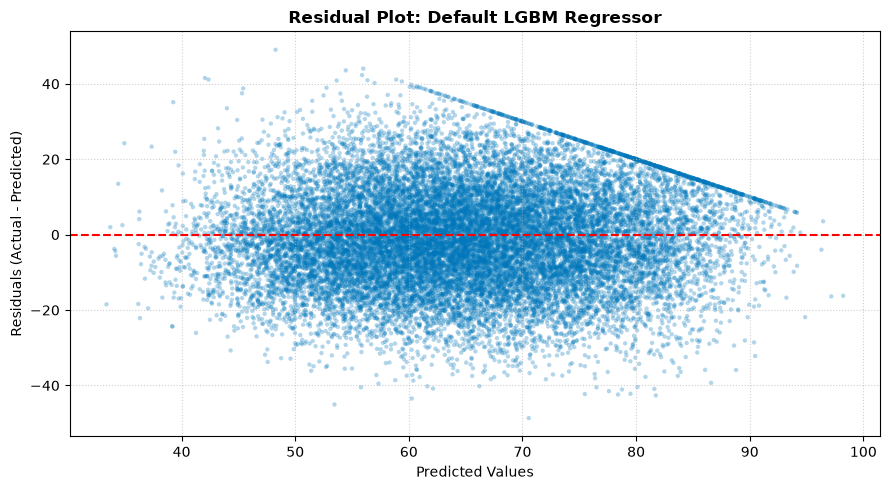

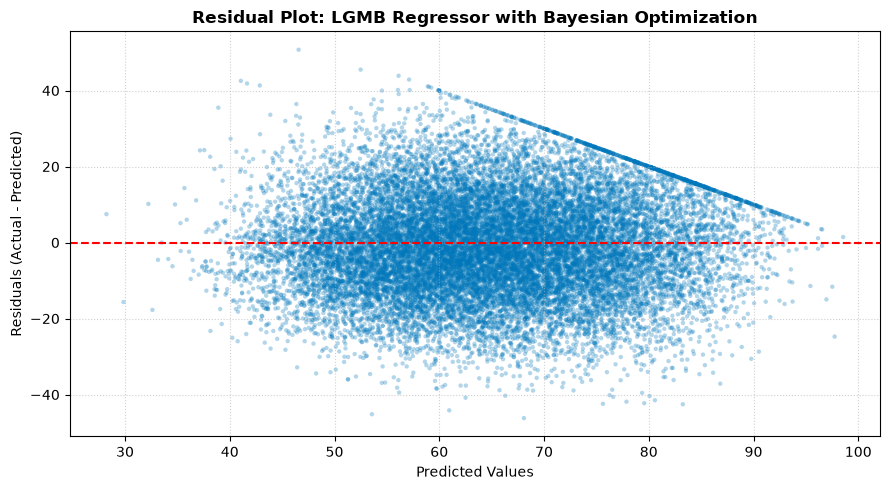

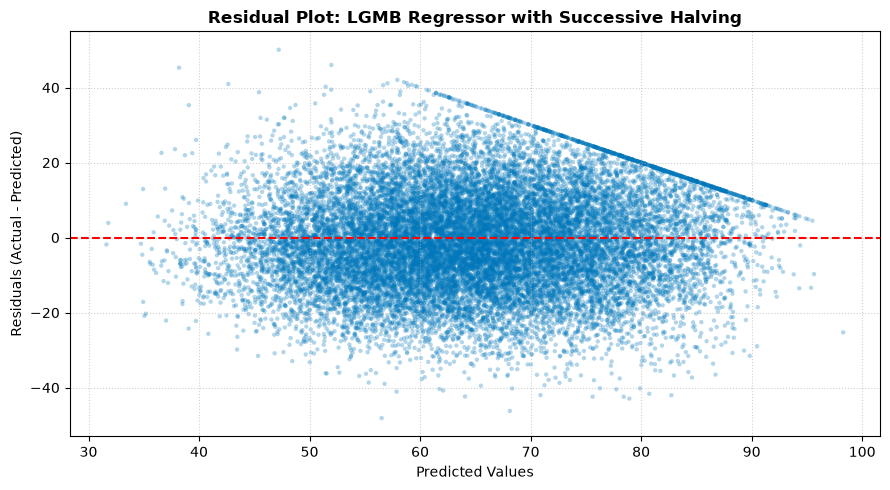

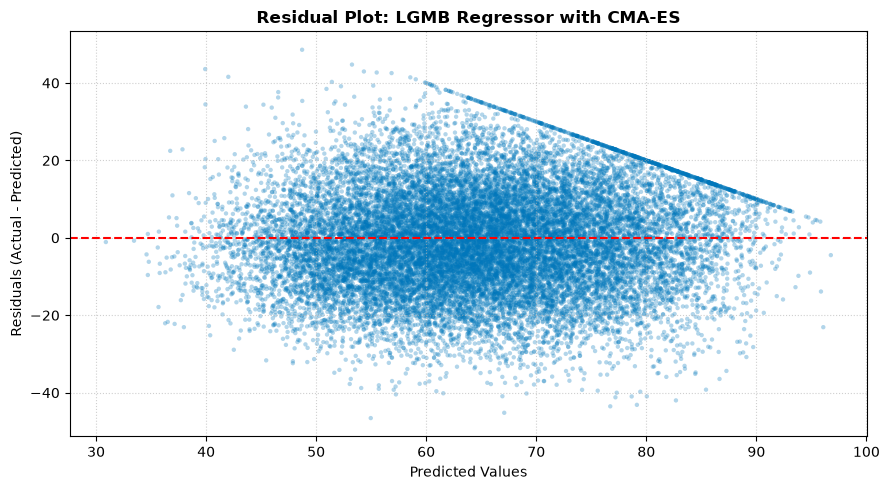

In [15]:
import matplotlib.pyplot as plt
import numpy as np

models = {
    "Default LGBM Regressor": predict_lgbm,
    "LGMB Regressor with Bayesian Optimization": predict_lgbm_bayesian,
    "LGMB Regressor with Successive Halving": predict_lgbm_successive_halving,
    "LGMB Regressor with CMA-ES": predict_lgbm_cmaes,
}

for name, predictions in models.items():
    y_true = np.asarray(y_test).flatten()
    y_pred = np.asarray(predictions).flatten()

    residuals = y_true - y_pred

    plt.figure(figsize=(9, 5))

    plt.scatter(
        y_pred, residuals, alpha=0.3, color="#0077BB", edgecolors="none", s=10
    )

    plt.axhline(0, color="red", linestyle="--", linewidth=1.5)

    plt.title(f"Residual Plot: {name}", fontsize=12, fontweight="bold")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.savefig(
        f"../results/model_comparison/residual_plot_tuned/{name.replace(" ", "_")}_residual_plot.png",
        dpi=300, 
        bbox_inches="tight"
    )
    plt.show()